In [1]:
import numpy as np # linear algebra
import pandas as pd #
data = pd.read_csv('crimedata_processing.csv')
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,r2_score

# 划分特征和目标变量
X = data.drop(["ViolentCrimesPerPop"], axis=1)
y = data["ViolentCrimesPerPop"]

# 划分训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [2]:
import lightgbm as lgb
from sklearn.metrics import confusion_matrix,accuracy_score,roc_curve,classification_report,f1_score,accuracy_score

# 创建模型
model = LinearRegression()

model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)
R2 = r2_score(y_test, y_pred)
R2

0.892953553835254

/opt/anaconda3/envs/XAI/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


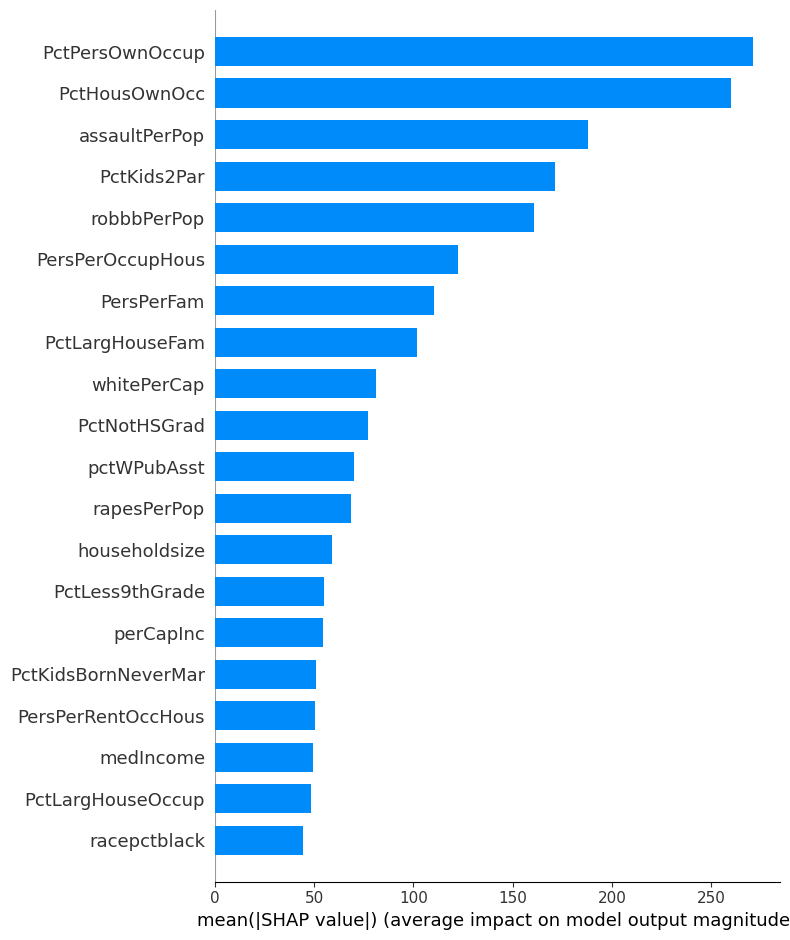

In [4]:
import shap
import time
s = time.time()
explainer = shap.Explainer(model,X_test)
shap_values = explainer.shap_values(X_test)
feature_names = X.columns.tolist()
shap.summary_plot(shap_values, X_test, plot_type="bar", feature_names=feature_names)

In [5]:
shap_values = explainer.shap_values(X_train)
feature_importance = np.abs(shap_values).mean(axis=0)
sorted_feature_indices = np.argsort(feature_importance)[::-1]
sorted_features = X_train.columns[sorted_feature_indices][:30]
sorted_features

Index(['PctPersOwnOccup', 'PctHousOwnOcc', 'assaultPerPop', 'PctKids2Par',
       'robbbPerPop', 'PersPerOccupHous', 'PersPerFam', 'PctLargHouseFam',
       'PctNotHSGrad', 'whitePerCap', 'pctWPubAsst', 'rapesPerPop',
       'PctLess9thGrade', 'householdsize', 'perCapInc', 'PctKidsBornNeverMar',
       'medIncome', 'PersPerRentOccHous', 'racepctblack', 'state_encoded',
       'medFamInc', 'PctLargHouseOccup', 'PctBornSameState', 'TotalPctDiv',
       'PctHousNoPhone', 'PctRecImmig5', 'nonViolPerPop', 'pctWInvInc',
       'PctFam2Par', 'PctRecentImmig'],
      dtype='object')

In [6]:
shap_df = pd.DataFrame(shap_values, columns=X_test.columns)
shap_values_per_feature = shap_df.abs().mean()  # Calculate the average absolute SHAP value per feature

# Sort SHAP values from largest to smallest
shap_values_per_feature_sorted = shap_values_per_feature.sort_values(ascending=False)

In [7]:
shap_values_per_feature_sorted

PctPersOwnOccup    276.111498
PctHousOwnOcc      262.106145
assaultPerPop      201.751989
PctKids2Par        175.480938
robbbPerPop        158.081314
                      ...    
NumInShelters        0.594543
PctSameCity85        0.582009
OtherPerCap          0.488188
arsons               0.212888
RentLowQ             0.115371
Length: 121, dtype: float64

In [8]:
print(shap_values_per_feature_sorted[:30])

PctPersOwnOccup        276.111498
PctHousOwnOcc          262.106145
assaultPerPop          201.751989
PctKids2Par            175.480938
robbbPerPop            158.081314
PersPerOccupHous       114.217589
PersPerFam             105.175000
PctLargHouseFam         93.557341
PctNotHSGrad            82.616591
whitePerCap             80.713163
pctWPubAsst             72.337436
rapesPerPop             65.955050
PctLess9thGrade         57.651633
householdsize           57.419418
perCapInc               54.434930
PctKidsBornNeverMar     54.188054
medIncome               48.455217
PersPerRentOccHous      47.338182
racepctblack            47.066125
state_encoded           44.357399
medFamInc               44.013893
PctLargHouseOccup       43.899910
PctBornSameState        43.579254
TotalPctDiv             42.249239
PctHousNoPhone          41.077269
PctRecImmig5            38.524928
nonViolPerPop           38.517839
pctWInvInc              37.322017
PctFam2Par              36.417874
PctRecentImmig

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import shap

# Assuming you have already calculated shap_values and x_test

# Generate the summary plot with bar chart
# shap.summary_plot(shap_values, x_test, plot_type="bar", show=False, color='c')

# Extract and display the SHAP values for each feature
shap_df = pd.DataFrame(shap_values, columns=X_test.columns)
shap_values_per_feature = shap_df.abs().mean()  # Calculate the average absolute SHAP value per feature

# Sort SHAP values from largest to smallest
shap_values_per_feature_sorted = shap_values_per_feature.sort_values(ascending=False)

# 最小-最大归一化到 [0, 1] 之间
shap_values_per_feature_normalized = (shap_values_per_feature - shap_values_per_feature.min()) / (shap_values_per_feature.max() - shap_values_per_feature.min())
shap_values_per_feature_normalized = shap_values_per_feature_normalized.sort_values(ascending=False)
shap_values_per_feature_normalized

PctPersOwnOccup    1.000000
PctHousOwnOcc      0.949255
assaultPerPop      0.730578
PctKids2Par        0.635391
robbbPerPop        0.572348
                     ...   
NumInShelters      0.001736
PctSameCity85      0.001691
OtherPerCap        0.001351
arsons             0.000353
RentLowQ           0.000000
Length: 121, dtype: float64

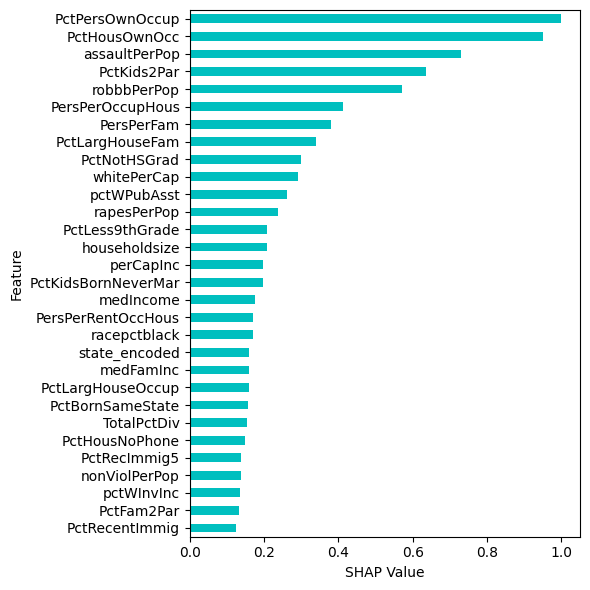

In [10]:
# Create a vertical figure for better spacing
plt.figure(figsize=(6, 6))
# colors = plt.cm.viridis(range(len(sorted_feature_importance_df)))

# colors = plt.color_palette("c", len(shap_values_per_feature_sorted))

# Plot the sorted SHAP values for each feature vertically
bar_plot = shap_values_per_feature_normalized[:30].plot(kind='barh', color='c')
# plt.title('SHAP Values for H1N1 Vaccine Features', fontsize=14)
plt.xlabel('SHAP Value')
plt.ylabel('Feature')
plt.gca().invert_yaxis()  # 反转y轴，使权重最大的特征位于顶部

# # Annotate the bars with SHAP values
# for i, value in enumerate(shap_values_per_feature_sorted):
#     bar_plot.text(value + 0.01, i, f'{value:.4f}', ha='left', va='center', fontsize=8)

plt.tight_layout()  # Adjusts subplot parameters to give specified padding

plt.savefig('shap_crime_lr_normalized.eps', format='eps', dpi=300)

plt.show()

In [4]:
import time
s = time.time()

from lime.lime_tabular import LimeTabularExplainer
explainer = LimeTabularExplainer(X_test.values,
                                 feature_names=X_train.columns.tolist(),
                                 mode='regression')
sample_idx =0# Choose an index of the test set
exp = explainer.explain_instance(X_test.iloc[sample_idx].values, model.predict, num_features=30)
feature_values = exp.as_list()

feature_values

/opt/anaconda3/envs/XAI/lib/python3.10/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


[('assaultPerPop > 485.88', 610.8172659816722),
 ('PctPersOwnOccup <= 57.94', 608.2400254626968),
 ('PctHousOwnOcc <= 55.22', -565.3923821744947),
 ('PersPerFam > 3.23', 355.3429266122777),
 ('PersPerOccupHous > 2.79', -348.095282433133),
 ('PctLargHouseFam > 6.17', -337.1026283416257),
 ('rapesPerPop > 48.94', 207.51302987183183),
 ('pctWPubAsst > 8.79', -193.15155163082682),
 ('PctLess9thGrade > 11.56', 173.20294042714153),
 ('PctNotHSGrad > 27.81', -171.21849630367595),
 ('PctLargHouseOccup > 4.33', 156.74732069222497),
 ('PctRecImmig5 > 2.22', 155.87797240272886),
 ('PersPerRentOccHous > 2.52', -144.48838750543504),
 ('larcPerPop > 4295.48', 138.53562651912992),
 ('PctRecentImmig > 1.45', -137.48230745871987),
 ('nonViolPerPop > 5974.45', -132.5186104831081),
 ('state_encoded > 699.20', 109.69588998736721),
 ('pctWInvInc <= 35.39', 98.72137074437433),
 ('burglaries > 524.00', -82.57598873714221),
 ('69.73 < robbbPerPop <= 192.26', -81.92924221917362),
 ('12604.50 < whitePerCap <= 1

In [5]:
e = time.time()
e-s

0.22113275527954102

In [13]:
# 提取特征值及其权重
feature_values = exp.as_map()[1]

# 根据权重的绝对值对特征进行排序
sorted_features = sorted(feature_values, key=lambda x: abs(x[1]), reverse=True)

# 提取特征名称和权重
features = [X_test.columns[i] for i, _ in sorted_features]
weights = [weight for _, weight in sorted_features]

# 打印排序后的特征及其权重（按绝对值排序）
# print("Sorted features by absolute weight (from largest to smallest):")
for feature, weight in zip(features, weights):
    print(f"Feature: {feature}, Weight: {abs(weight)}")

Feature: assaultPerPop, Weight: 585.0849127212402
Feature: PctPersOwnOccup, Weight: 581.8612402053573
Feature: PctHousOwnOcc, Weight: 564.7225331678131
Feature: PctLargHouseFam, Weight: 368.2713411896518
Feature: PersPerFam, Weight: 344.5873460088684
Feature: PersPerOccupHous, Weight: 340.7555712744712
Feature: pctWPubAsst, Weight: 222.80019455890584
Feature: rapesPerPop, Weight: 203.10015303702912
Feature: PctLess9thGrade, Weight: 189.52225162722834
Feature: PctNotHSGrad, Weight: 176.66825707134828
Feature: PersPerRentOccHous, Weight: 164.02943737057313
Feature: PctLargHouseOccup, Weight: 162.8191332012171
Feature: PctRecentImmig, Weight: 142.59771830898038
Feature: nonViolPerPop, Weight: 139.40557538518155
Feature: PctRecImmig5, Weight: 123.90355024309515
Feature: burglaries, Weight: 107.44964492737301
Feature: state_encoded, Weight: 91.64643224059192
Feature: perCapInc, Weight: 89.92630257240315
Feature: larcPerPop, Weight: 83.02558204584022
Feature: whitePerCap, Weight: 75.27792729

In [14]:
abs_weights = [abs(weight) for weight in weights]
# 归一化处理
min_abs_weight = min(abs_weights)
max_abs_weight = max(abs_weights)
normalized_weights = [(w - min_abs_weight) / (max_abs_weight - min_abs_weight) for w in abs_weights]
normalized_weights

[1.0,
 0.9939900731245676,
 0.9620381997479733,
 0.5957921581407031,
 0.5516378346313203,
 0.5444942163377763,
 0.32458875598723463,
 0.28786175955502014,
 0.2625483338913768,
 0.23858449545635313,
 0.21502180978676727,
 0.2127654268821693,
 0.17506642854367457,
 0.16911528262130243,
 0.1402146926680652,
 0.1095395024074026,
 0.0800774053189065,
 0.07687054932744274,
 0.06400546283118638,
 0.04956142787016697,
 0.04877959039739282,
 0.02194713292258857,
 0.019876969957972723,
 0.016465860269693773,
 0.015425041244758691,
 0.014258763867163378,
 0.011525515389149485,
 0.010937593567221559,
 0.0075389242144764685,
 0.0]

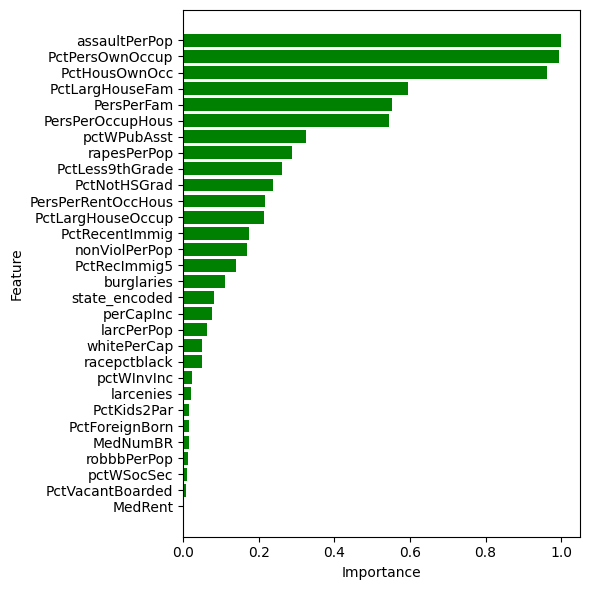

In [15]:
import matplotlib.pyplot as plt
import numpy as np

# 计算绝对权重
abs_weights = [abs(weight) for weight in weights]

# 归一化处理
min_abs_weight = min(abs_weights)
max_abs_weight = max(abs_weights)
normalized_weights = [(w - min_abs_weight) / (max_abs_weight - min_abs_weight) for w in abs_weights]

# 绘制归一化后的特征权重条形图
plt.figure(figsize=(6, 6))
plt.barh(features[:30], normalized_weights[:30], color='g')  # 使用归一化后的权重
plt.xlabel('Importance')  # 修改x轴标签
plt.ylabel('Feature')
# plt.title('LIME Feature Weights (Normalized Absolute Values)')  # 修改标题
plt.gca().invert_yaxis()  # 反转y轴，使权重最大的特征位于顶部
plt.tight_layout()

# 保存图像为300 dpi的EPS格式
plt.savefig('lime_crime_lr_normalized.eps', format='eps', dpi=300)

# 显示图像
plt.show()

In [16]:
from sklearn.inspection import permutation_importance
import numpy as np
result = permutation_importance(model, X_test, y_test, n_repeats=10, random_state=42, scoring='neg_mean_squared_error')

# 打印特征重要性
feature_names = X.columns.tolist()
importances = result.importances_mean
std = result.importances_std
indices = np.argsort(importances)[::-1]

print("Feature ranking:")
for f in range(X_test.shape[1]):
    print(f"{f + 1}. feature {feature_names[indices[f]]} ({importances[indices[f]]:.6f})")

Feature ranking:
1. feature PctPersOwnOccup (214466.135383)
2. feature PctHousOwnOcc (202532.831830)
3. feature assaultPerPop (162059.534645)
4. feature robbbPerPop (124017.785438)
5. feature PctKids2Par (92213.506048)
6. feature PctLargHouseFam (54627.270391)
7. feature PersPerFam (52429.953383)
8. feature PersPerOccupHous (51268.595195)
9. feature whitePerCap (26789.037966)
10. feature rapesPerPop (17983.995774)
11. feature PctNotHSGrad (17671.555055)
12. feature pctWPubAsst (16888.300422)
13. feature PctLargHouseOccup (14725.064396)
14. feature householdsize (13326.295733)
15. feature perCapInc (12485.088333)
16. feature PctKidsBornNeverMar (12450.956811)
17. feature racepctblack (12411.282771)
18. feature PctLess9thGrade (12102.845550)
19. feature rapes (11131.611446)
20. feature PctRecImmig5 (9676.195650)
21. feature nonViolPerPop (8970.880455)
22. feature PersPerRentOccHous (7581.375784)
23. feature medIncome (7532.088754)
24. feature medFamInc (6547.303897)
25. feature PctRecent

In [6]:
import time
s = time.time()

In [7]:
from sklearn.inspection import permutation_importance
import numpy as np
result = permutation_importance(model, X_test, y_test, n_repeats=1, random_state=42, scoring='neg_mean_squared_error')

# 打印特征重要性
feature_names = X.columns.tolist()
importances = result.importances_mean
std = result.importances_std
indices = np.argsort(importances)[::-1]

print("Feature ranking:")
for f in range(X_test.shape[1]):
    print(f"{f + 1}. feature {feature_names[indices[f]]} ({importances[indices[f]]:.6f})")

Feature ranking:
1. feature PctPersOwnOccup (202855.629290)
2. feature PctHousOwnOcc (187549.399539)
3. feature assaultPerPop (162195.975659)
4. feature robbbPerPop (114552.552130)
5. feature PctKids2Par (90781.968030)
6. feature PctLargHouseFam (57589.459540)
7. feature PersPerOccupHous (50586.466921)
8. feature PersPerFam (50168.199802)
9. feature whitePerCap (25836.951149)
10. feature PctNotHSGrad (16741.615119)
11. feature rapesPerPop (16494.243305)
12. feature pctWPubAsst (14545.339199)
13. feature PctLargHouseOccup (13745.965318)
14. feature perCapInc (13592.576479)
15. feature PctLess9thGrade (13358.313116)
16. feature racepctblack (11918.843334)
17. feature PctKidsBornNeverMar (11476.957428)
18. feature householdsize (11434.285238)
19. feature rapes (11195.644275)
20. feature PctRecImmig5 (9590.945848)
21. feature nonViolPerPop (9084.250597)
22. feature medIncome (8070.422207)
23. feature PersPerRentOccHous (6770.073120)
24. feature state_encoded (6035.528669)
25. feature PctRe

In [8]:
e = time.time()
e-s

0.4979398250579834

In [18]:
# 归一化处理
min_importance = np.min(importances)
max_importance = np.max(importances)
normalized_importances = (importances - min_importance) / (max_importance - min_importance)

# 按归一化后的重要性排序
indices = np.argsort(normalized_importances)[::-1]

# 打印归一化后的特征重要性
print("Feature ranking (normalized importance):")
for f in range(X_test.shape[1]):
    print(f"{f + 1}. feature {feature_names[indices[f]]} ({normalized_importances[indices[f]]:.6f})")

Feature ranking (normalized importance):
1. feature PctPersOwnOccup (1.000000)
2. feature PctHousOwnOcc (0.924914)
3. feature assaultPerPop (0.800541)
4. feature robbbPerPop (0.566822)
5. feature PctKids2Par (0.450214)
6. feature PctLargHouseFam (0.287385)
7. feature PersPerOccupHous (0.253032)
8. feature PersPerFam (0.250980)
9. feature whitePerCap (0.131621)
10. feature PctNotHSGrad (0.087003)
11. feature rapesPerPop (0.085789)
12. feature pctWPubAsst (0.076229)
13. feature PctLargHouseOccup (0.072307)
14. feature perCapInc (0.071555)
15. feature PctLess9thGrade (0.070406)
16. feature racepctblack (0.063344)
17. feature PctKidsBornNeverMar (0.061177)
18. feature householdsize (0.060967)
19. feature rapes (0.059797)
20. feature PctRecImmig5 (0.051925)
21. feature nonViolPerPop (0.049439)
22. feature medIncome (0.044466)
23. feature PersPerRentOccHous (0.038087)
24. feature state_encoded (0.034483)
25. feature PctRecentImmig (0.033538)
26. feature medFamInc (0.031608)
27. feature PctHo

In [19]:
# 创建一个数据框来存储特征及其重要性
feature_importance_df = pd.DataFrame({
    'Feature': [feature_names[i] for i in indices],
    'Importance': normalized_importances[indices],
    'Std': std[indices]
})

# 按重要性排序
sorted_feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

sorted_feature_importance_30 = sorted_feature_importance_df[:30]
sorted_feature_importance_30

,Feature,Importance,Std
0,PctPersOwnOccup,1.000000,0.0
1,PctHousOwnOcc,0.924914,0.0
2,assaultPerPop,0.800541,0.0
3,robbbPerPop,0.566822,0.0
4,PctKids2Par,0.450214,0.0
5,PctLargHouseFam,0.287385,0.0
6,PersPerOccupHous,0.253032,0.0
7,PersPerFam,0.250980,0.0
8,whitePerCap,0.131621,0.0
9,PctNotHSGrad,0.087003,0.0


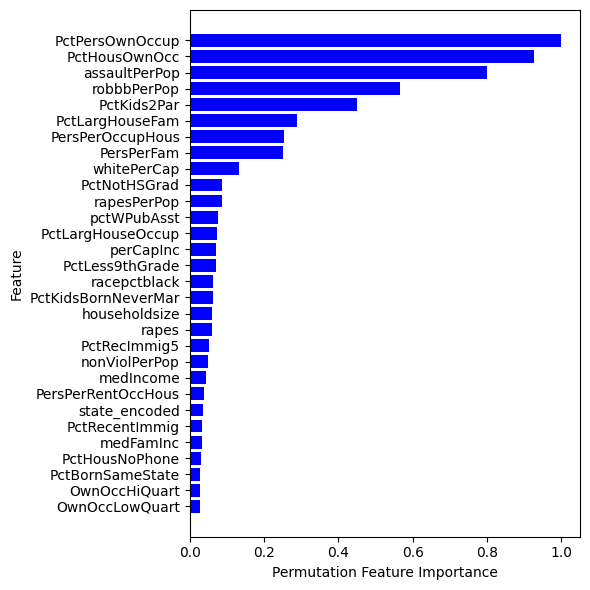

In [20]:
# 画图
plt.figure(figsize=(6, 6))  # 改变图形大小，使其适应竖向显示
plt.barh(sorted_feature_importance_30['Feature'], sorted_feature_importance_30['Importance'], color='b')
plt.ylabel('Feature')
plt.xlabel('Permutation Feature Importance')
# plt.gca().invert_yaxis()  # 反转y轴，使重要性最高的特征位于顶部
plt.tight_layout()
plt.gca().invert_yaxis()  # 反转y轴，使权重最大的特征位于顶部


# 保存图像为300 dpi的EPS格式
plt.savefig('Permutation_importance_crime_lr_normalized.eps', format='eps', dpi=300)

# 显示图像
plt.show()

100%|██████████| 1772/1772 [2:15:30<00:00,  4.59s/it]  


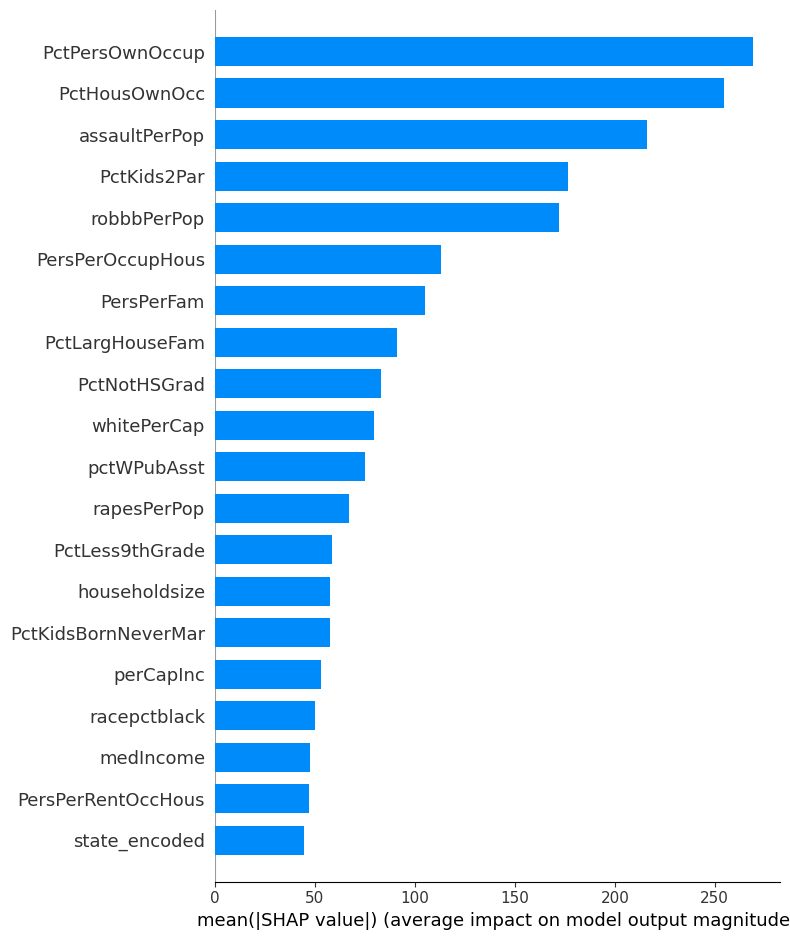

In [26]:
# 使用 SHAP 解释模型
import time

s= time.time()
Sampling_explainer = shap.SamplingExplainer(model.predict, X_train) 
Sampling_shap_values = Sampling_explainer.shap_values(X_train) 

# 获取特征名称
feature_names = X_train.columns.tolist()

# 绘制 SHAP 摘要图
shap.summary_plot(Sampling_shap_values, X_train, plot_type="bar", feature_names=feature_names)

In [27]:
e = time.time()
e-s

8131.12212395668

In [28]:
# shap_values = explainer.shap_values(X_test)
Samplingfeature_importance = np.abs(Sampling_shap_values).mean(axis=0)
Samplingsorted_feature_indices = np.argsort(Samplingfeature_importance)[::-1]
Samplingsorted_features = X_train.columns[Samplingsorted_feature_indices][:30]
Samplingsorted_features

Index(['PctPersOwnOccup', 'PctHousOwnOcc', 'assaultPerPop', 'PctKids2Par',
       'robbbPerPop', 'PersPerOccupHous', 'PersPerFam', 'PctLargHouseFam',
       'PctNotHSGrad', 'whitePerCap', 'pctWPubAsst', 'rapesPerPop',
       'PctLess9thGrade', 'householdsize', 'PctKidsBornNeverMar', 'perCapInc',
       'racepctblack', 'medIncome', 'PersPerRentOccHous', 'state_encoded',
       'medFamInc', 'PctBornSameState', 'TotalPctDiv', 'PctLargHouseOccup',
       'PctHousNoPhone', 'PctRecImmig5', 'nonViolPerPop', 'pctWInvInc',
       'PctFam2Par', 'PctRecentImmig'],
      dtype='object')

In [29]:
# Extract and display the SHAP values for each feature
shap_df = pd.DataFrame(Sampling_shap_values, columns=X_test.columns)
shap_values_per_feature = shap_df.abs().mean()  # Calculate the average absolute SHAP value per feature

# Sort SHAP values from largest to smallest
shap_values_per_feature_sorted = shap_values_per_feature.sort_values(ascending=True)
shap_values_per_feature_sorted

RentLowQ             0.114739
arsons               0.282837
OtherPerCap          0.485813
PctSameCity85        0.583911
NumInShelters        0.736590
                      ...    
robbbPerPop        172.132907
PctKids2Par        176.545320
assaultPerPop      216.170546
PctHousOwnOcc      254.480009
PctPersOwnOccup    269.142969
Length: 121, dtype: float64

In [30]:
shap_values_per_feature_sorted[:30]

RentLowQ               0.114739
arsons                 0.282837
OtherPerCap            0.485813
PctSameCity85          0.583911
NumInShelters          0.736590
RentQrange             0.742542
LandArea               0.915317
PctOccupManu           0.937595
blackPerCap            1.060670
indianPerCap           1.080549
PctWorkMomYoungKids    1.108756
pctWWage               1.124794
communityName_freq     1.506507
PctHousOccup           1.518073
assaults               1.555913
FemalePctDiv           1.642283
PctWorkMom             1.662183
RentHighQ              1.784224
racePctHisp            1.841638
LemasPctOfficDrugUn    2.263269
PctRecImmig8           2.343178
agePct16t24            2.980003
larcenies              3.003870
autoTheftPerPop        3.283405
pctWFarmSelf           3.370207
autoTheft              3.562954
population             3.601432
MedRentPctHousInc      3.607594
HispPerCap             3.895169
arsonsPerPop           3.991118
dtype: float64

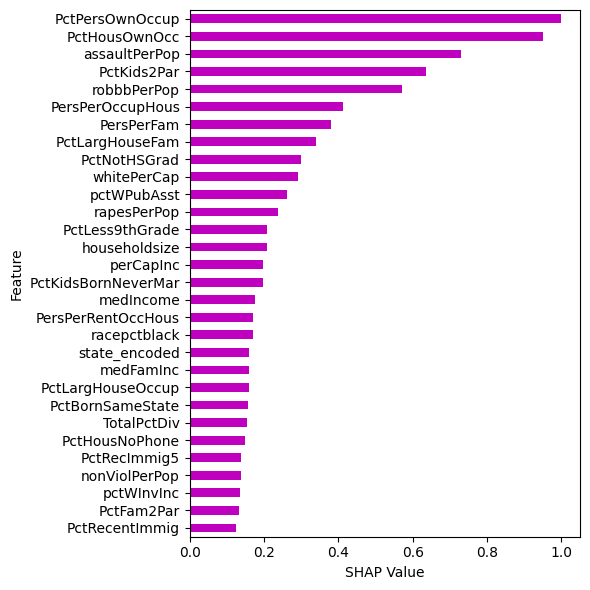

In [31]:
# Create a vertical figure for better spacing
plt.figure(figsize=(6, 6))
# colors = plt.cm.viridis(range(len(sorted_feature_importance_df)))

# colors = plt.color_palette("c", len(shap_values_per_feature_sorted))

# Plot the sorted SHAP values for each feature vertically
bar_plot = shap_values_per_feature_normalized[:30].plot(kind='barh', color='m')
# plt.title('SHAP Values for H1N1 Vaccine Features', fontsize=14)
plt.xlabel('SHAP Value')
plt.ylabel('Feature')
plt.gca().invert_yaxis()  # 反转y轴，使权重最大的特征位于顶部

# # Annotate the bars with SHAP values
# for i, value in enumerate(shap_values_per_feature_sorted):
#     bar_plot.text(value + 0.01, i, f'{value:.4f}', ha='left', va='center', fontsize=8)

plt.tight_layout()  # Adjusts subplot parameters to give specified padding

plt.savefig('Samplingshap_crime_lr_normalized.eps', format='eps', dpi=300)

plt.show()

Using 1772 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.


100%|██████████| 1772/1772 [3:07:26<00:00,  6.35s/it]  


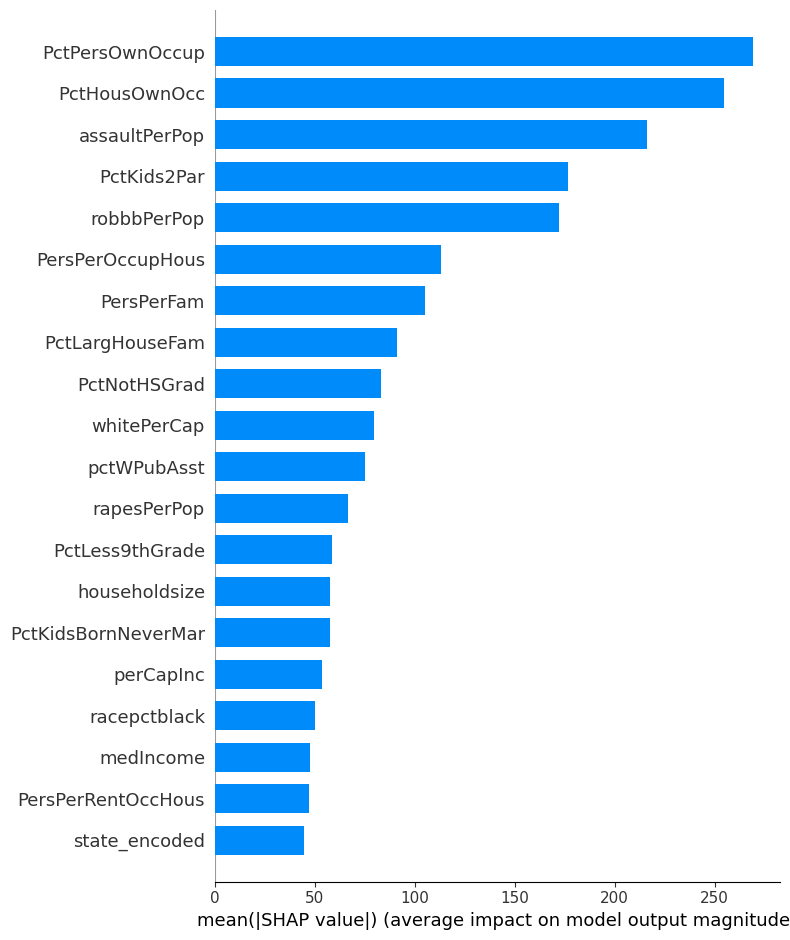

In [32]:
s= time.time()
Kernel_explainer = shap.KernelExplainer(model.predict, X_train) 
Kernel_shap_values = Kernel_explainer.shap_values(X_train) 

# 获取特征名称
feature_names = X_train.columns.tolist()

# 绘制 SHAP 摘要图
shap.summary_plot(Kernel_shap_values, X_train, plot_type="bar", feature_names=feature_names)

In [33]:
e = time.time()
e-s

11246.562328100204

In [34]:
Kernel_feature_importance = np.abs(Kernel_shap_values).mean(axis=0)
Kernel_sorted_feature_indices = np.argsort(Kernel_feature_importance)[::-1]
Kernel_sorted_features = X.columns[Kernel_sorted_feature_indices][:30]
Kernel_sorted_features

Index(['PctPersOwnOccup', 'PctHousOwnOcc', 'assaultPerPop', 'PctKids2Par',
       'robbbPerPop', 'PersPerOccupHous', 'PersPerFam', 'PctLargHouseFam',
       'PctNotHSGrad', 'whitePerCap', 'pctWPubAsst', 'rapesPerPop',
       'PctLess9thGrade', 'householdsize', 'PctKidsBornNeverMar', 'perCapInc',
       'racepctblack', 'medIncome', 'PersPerRentOccHous', 'state_encoded',
       'medFamInc', 'PctBornSameState', 'TotalPctDiv', 'PctLargHouseOccup',
       'PctHousNoPhone', 'PctRecImmig5', 'nonViolPerPop', 'pctWInvInc',
       'PctFam2Par', 'rapes'],
      dtype='object')

In [40]:
# Extract and display the SHAP values for each feature
shap_df = pd.DataFrame(Kernel_shap_values, columns=X_test.columns)
shap_values_per_feature = shap_df.abs().mean()  # Calculate the average absolute SHAP value per feature

# Sort SHAP values from largest to smallest
shap_values_per_feature_sorted = shap_values_per_feature.sort_values(ascending=False)
shap_values_per_feature_sorted

PctPersOwnOccup    269.148718
PctHousOwnOcc      254.466313
assaultPerPop      216.208522
PctKids2Par        176.499955
robbbPerPop        172.196875
                      ...    
RentQrange           0.738793
PctSameCity85        0.580003
OtherPerCap          0.480993
arsons               0.276179
RentLowQ             0.114563
Length: 121, dtype: float64

In [41]:
shap_values_per_feature_sorted[:30]

PctPersOwnOccup        269.148718
PctHousOwnOcc          254.466313
assaultPerPop          216.208522
PctKids2Par            176.499955
robbbPerPop            172.196875
PersPerOccupHous       113.018138
PersPerFam             105.262825
PctLargHouseFam         91.137169
PctNotHSGrad            82.850023
whitePerCap             79.790502
pctWPubAsst             74.834499
rapesPerPop             66.738792
PctLess9thGrade         58.562036
householdsize           57.625695
PctKidsBornNeverMar     57.454278
perCapInc               53.382847
racepctblack            49.956091
medIncome               47.701428
PersPerRentOccHous      47.094374
state_encoded           44.685923
medFamInc               43.339709
PctBornSameState        43.107102
TotalPctDiv             42.045612
PctLargHouseOccup       41.909907
PctHousNoPhone          41.555496
PctRecImmig5            39.581283
nonViolPerPop           38.711638
pctWInvInc              36.692089
PctFam2Par              36.541929
rapes         

In [42]:
shap_values_per_feature_normalized = (shap_values_per_feature - shap_values_per_feature.min()) / (shap_values_per_feature.max() - shap_values_per_feature.min())
shap_values_per_feature_normalized = shap_values_per_feature_normalized.sort_values(ascending=False)
shap_values_per_feature_normalized

PctPersOwnOccup    1.000000
PctHousOwnOcc      0.945425
assaultPerPop      0.803221
PctKids2Par        0.655625
robbbPerPop        0.639630
                     ...   
RentQrange         0.002320
PctSameCity85      0.001730
OtherPerCap        0.001362
arsons             0.000601
RentLowQ           0.000000
Length: 121, dtype: float64

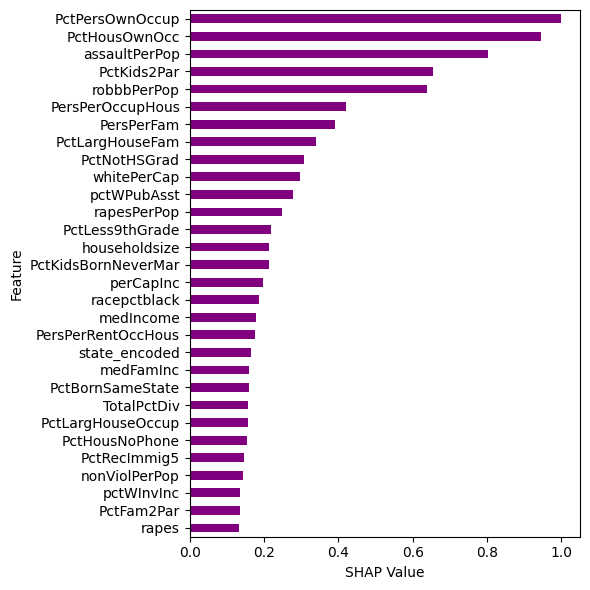

In [44]:
# Create a vertical figure for better spacing
plt.figure(figsize=(6, 6))
# colors = plt.cm.viridis(range(len(sorted_feature_importance_df)))

# colors = plt.color_palette("c", len(shap_values_per_feature_sorted))

# Plot the sorted SHAP values for each feature vertically
bar_plot = shap_values_per_feature_normalized[:30].plot(kind='barh', color='purple')
# plt.title('SHAP Values for H1N1 Vaccine Features', fontsize=14)
plt.xlabel('SHAP Value')
plt.ylabel('Feature')
plt.gca().invert_yaxis()  # 反转y轴，使权重最大的特征位于顶部

# # Annotate the bars with SHAP values
# for i, value in enumerate(shap_values_per_feature_sorted):
#     bar_plot.text(value + 0.01, i, f'{value:.4f}', ha='left', va='center', fontsize=8)

plt.tight_layout()  # Adjusts subplot parameters to give specified padding

plt.savefig('Kernelshap_crime_lr_normalized.eps', format='eps', dpi=300)

plt.show()